In [19]:
import pandas as pd
import pandas as np

In [20]:
df = pd.read_parquet("../data/cleaned_merged_df.parquet")


In [21]:
doctor_performance = (
    df.groupby(["doctor_id", "doctor", "doctors_specialization"])
    .agg(
        admissions=("admission_id", "nunique"),
        median_duration=("admission_duration", "median"),
        mean_duration=("admission_duration", "mean"),
        deaths=("dead", lambda x: x.astype(str).str.strip().str.lower().eq("yes").sum()),
        dama=("dama", lambda x: x.astype(str).str.strip().str.lower().eq("yes").sum())
    )
)

doctor_performance["death_rate_pct"] = (
    doctor_performance["deaths"]
    / df.groupby(["doctor_id", "doctor", "doctors_specialization"])["dead"]
        .apply(lambda x: x.astype(str).str.strip().str.lower().isin(["yes", "no"]).sum())
    * 100
).round(2)

doctor_performance["dama_rate_pct"] = (
    doctor_performance["dama"]
    / df.groupby(["doctor_id", "doctor", "doctors_specialization"])["dama"]
        .apply(lambda x: x.astype(str).str.strip().str.lower().isin(["yes", "no"]).sum())
    * 100
).round(2)

doctor_performance = doctor_performance.sort_values(
    "admissions", ascending=False
).reset_index().round(2)

doctor_performance.head(10)

,doctor_id,doctor,doctors_specialization,admissions,median_duration,mean_duration,deaths,dama,death_rate_pct,dama_rate_pct
0,d028,dr ogbu,emergency medicine,210,6.0,10.15,93,33,44.29,15.71
1,d029,dr ogedegbe,emergency medicine,174,8.0,10.71,28,49,16.09,28.16
2,d009,dr abah,cardiology,143,11.0,13.17,26,20,18.18,13.99
3,d001,dr adedapo,cardiology,101,12.0,16.77,13,20,12.87,19.80
4,d004,dr solanke,nephrology,89,11.0,13.30,22,12,24.72,13.48
5,d025,dr lash,dermatology,68,10.0,13.54,18,3,26.47,4.41
6,d020,dr badmus,general surgery,52,9.5,10.62,14,15,26.92,28.85
7,d021,dr daniel,general surgery,47,10.0,12.32,1,14,2.13,29.79
8,d007,dr ekwe,general surgery,43,12.0,14.77,1,13,2.33,30.23
9,d035,dr davies,nephrology,42,11.5,12.50,2,3,4.76,7.14


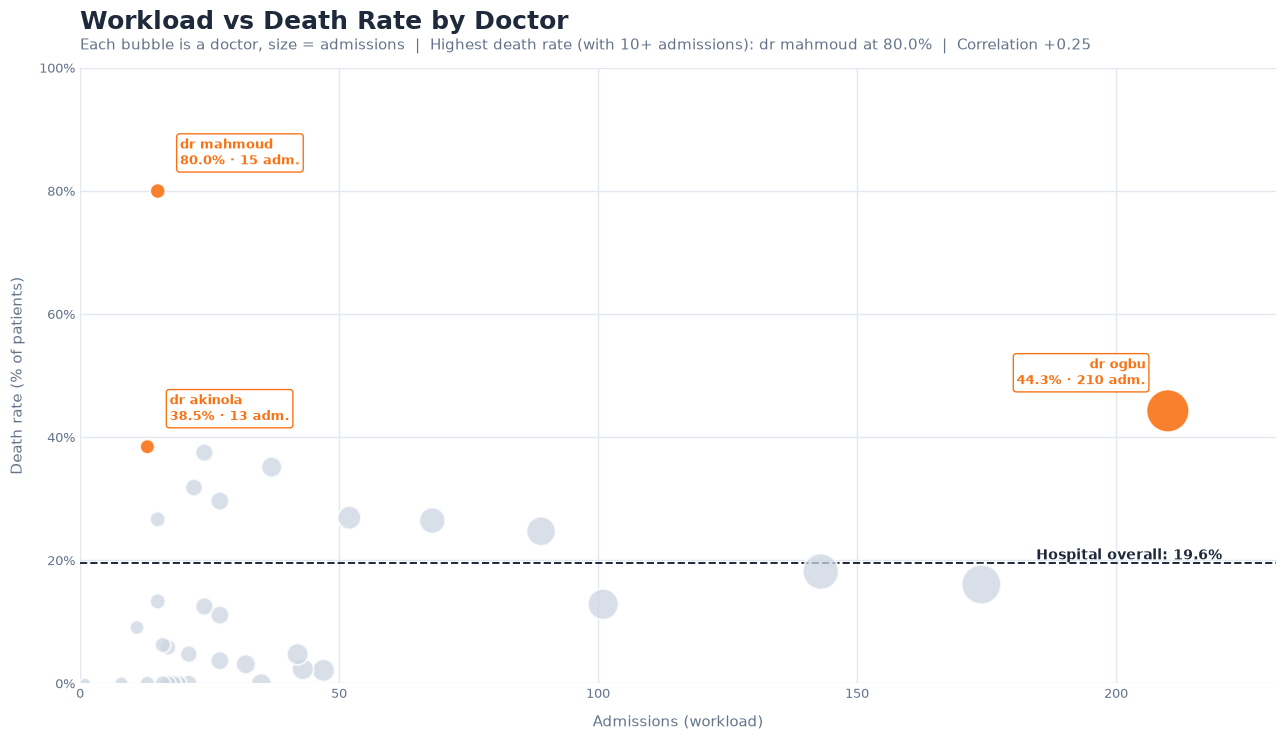

In [22]:
import os
import textwrap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --- Palette (same as the other charts) ---
BASE  = "#CBD5E1"
PEAK  = "#F97316"
TEXT  = "#1E293B"
MUTED = "#64748B"
GRID  = "#E2E8F0"

N_LABEL = 3    # how many highest-death-rate doctors to highlight and label
MIN_ADM = 10   # only doctors with at least this many admissions can be highlighted (too noisy otherwise)

# ---------------- Prep ----------------
data = doctor_performance.dropna(subset=["admissions", "death_rate_pct"]).reset_index(drop=True)
x = data["admissions"]
y = data["death_rate_pct"]
sizes = 60 + (x / x.max()) * 900

# Hospital-wide death rate (patients with a recorded yes/no outcome)
dead_s  = df["dead"].astype(str).str.strip().str.lower()
overall = dead_s[dead_s.isin(["yes", "no"])].eq("yes").mean() * 100

# Doctors to highlight: highest death rates among doctors with enough admissions
cand = data[data["admissions"] >= MIN_ADM]
if cand.empty:
    cand = data
top_idx = list(cand.nlargest(N_LABEL, "death_rate_pct").index)
is_top  = data.index.isin(top_idx)
busiest = int(x.values.argmax())

corr = np.corrcoef(x, y)[0, 1] if len(data) > 2 else np.nan

# ---------------- Plot ----------------
fig, ax = plt.subplots(figsize=(13, 7.5))
fig.patch.set_facecolor("white")

# Overall death rate reference line
ax.axhline(overall, color=TEXT, linestyle="--", linewidth=1.4, zorder=2)
ax.text(x.max() * 1.05, overall, f"Hospital overall: {overall:.1f}%", ha="right",
        va="bottom", fontsize=10, color=TEXT, fontweight="bold")

# Bubbles
ax.scatter(x[~is_top], y[~is_top], s=sizes[~is_top], color=BASE, alpha=0.75,
           edgecolor="white", linewidth=1.5, zorder=3)
ax.scatter(x[is_top], y[is_top], s=sizes[is_top], color=PEAK, alpha=0.9,
           edgecolor="white", linewidth=1.5, zorder=4)

# Labels (white pills so they stay readable)
def tag(i, color, bold):
    right_side = x.iloc[i] > x.max() * 0.8
    pill = dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, linewidth=1)
    ax.annotate(f"{textwrap.shorten(str(data['doctor'].iloc[i]), 24, placeholder='…')}\n"
                f"{y.iloc[i]:.1f}% · {int(x.iloc[i]):,} adm.",
                (x.iloc[i], y.iloc[i]),
                xytext=(-16, 16) if right_side else (16, 16), textcoords="offset points",
                ha="right" if right_side else "left", va="bottom", fontsize=9.5,
                fontweight="bold" if bold else "normal", color=color,
                bbox=pill, zorder=6)

for i in np.where(is_top)[0]:
    tag(int(i), PEAK, True)
if not is_top[busiest]:
    tag(busiest, MUTED, False)   # also label the busiest doctor for context

# Titles
top = data.loc[top_idx[0]]
ax.set_title("Workload vs Death Rate by Doctor", loc="left", fontsize=18,
             fontweight="bold", color=TEXT, pad=28)
ax.text(0, 1.03,
        f"Each bubble is a doctor, size = admissions  |  Highest death rate (with {MIN_ADM}+ admissions): "
        f"{textwrap.shorten(str(top['doctor']), 24, placeholder='…')} at {top['death_rate_pct']:.1f}%  |  "
        f"Correlation {corr:+.2f}",
        transform=ax.transAxes, fontsize=11, color=MUTED)

# Axes
px = (x.max() - x.min()) * 0.1 or 1
ax.set_xlim(max(0, x.min() - px), x.max() + px)
ax.set_ylim(0, max(y.max(), overall) * 1.25)
ax.set_xlabel("Admissions (workload)", fontsize=11, color=MUTED, labelpad=10)
ax.set_ylabel("Death rate (% of patients)", fontsize=11, color=MUTED, labelpad=10)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.tick_params(axis="both", labelsize=9, colors=MUTED, length=0)

# Clean look
ax.set_axisbelow(True)
ax.grid(color=GRID, linewidth=1, zorder=0)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

plt.tight_layout()

plt.savefig("../images/doctor_workload_vs_death_rate.png", dpi=180)
plt.show()

In [23]:
df["doctor"].nunique()

35